# Camera Calibration

### Worked example 1 · From millimetres to pixels
A 1920 × 1080 automotive camera has f = 6 mm and 3 μm (0.003 mm) pixels, principal point
at the image centre.
Pixel density mx = my = 1 / 0.003 ≈ 333.3 px/mm, so fx = fy = 333.3 × 6 = 2000 px. Principal
point (ox, oy) = (960, 540).
A point at (xc, yc, zc) = (0.5, 0.25, 10) m in the camera frame:
u = 2000 × 0.5/10 + 960 = 1060, v = 2000 × 0.25/10 + 540 = 590

In [23]:
import numpy as np
import matplotlib.pyplot as plt

f_mm = 6.0
pixel_mm = 0.003
W,H = 1920, 1080

mx = my = 1/pixel_mm
fx, fy = mx * f_mm, my * f_mm
ox, oy = W/2, H/2

print(f"m = {mx:.1f} px/mm, fx = {fx:.0f}, fy = {fy:.0f}, principal point = ({ox:.0f}, {oy:.0f})")

def cam_to_pixel(Xc):
    x, y, z = Xc
    return fx * x / z + ox, fy * y / z + oy

u, v = cam_to_pixel((0.5, 0.25, 10.0))
print(f"(u, v) = ({u:.0f}, {v:.0f})")

m = 333.3 px/mm, fx = 2000, fy = 2000, principal point = (960, 540)
(u, v) = (1060, 590)


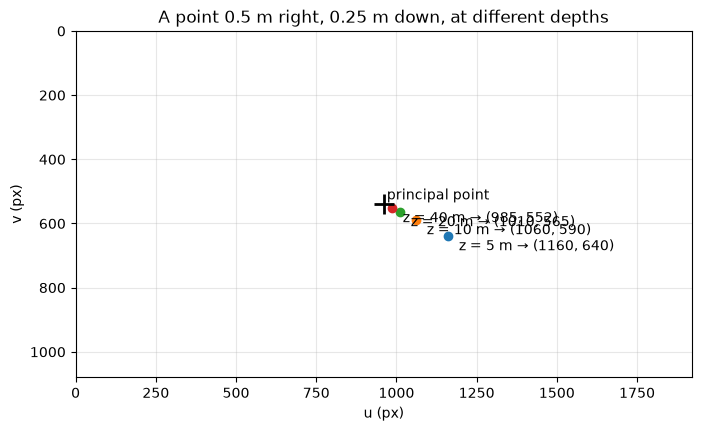

In [24]:
plt.figure(figsize=(8, 4.5))
for z in [5, 10, 20, 40]:
    u, v = cam_to_pixel((0.5, 0.25, z))
    plt.plot(u, v, "o")
    plt.annotate(f"z = {z} m → ({u:.0f}, {v:.0f})", (u, v), xytext=(8, -10), textcoords="offset points")
plt.plot(ox, oy, "k+", ms=14, mew=2)
plt.text(ox + 10, oy - 15, "principal point")
plt.xlim(0, W); plt.ylim(H, 0)           
plt.gca().set_aspect("equal")
plt.xlabel("u (px)"); plt.ylabel("v (px)")
plt.title("A point 0.5 m right, 0.25 m down, at different depths")
plt.grid(alpha=0.3)
plt.show()

### Worked example 2 · Converting homogeneous coordinates
(6, 4, 2) → (6/2, 4/2) = (3, 2). Also (3, 2, 1) → (3, 2) and (−3, −2, −1) → (3, 2): all the same
pixel.
In code: uv = x[:2] / x[2].

In [25]:
import numpy as np

def to_homogeneous(pts):
    pts = np.atleast_2d(np.asarray(pts, float))
    return np.hstack([pts, np.ones((len(pts),1))])

def from_homogeneous(pts_h):
    pts_h = np.atleast_2d(np.asarray(pts_h, float))
    return pts_h[:,:-1]/pts_h[:,-1:]

print(from_homogeneous([[6, 4, 2],
                        [3, 2, 1],
                        [-3, -2, -1]]))

[[3. 2.]
 [3. 2.]
 [3. 2.]]


Scaling doesn’t change the point

In [26]:
p = np.array([3.0, 2.0, 1.0])
for k in [1, 2, -1, 0.5, 100]:
    print(f"k = {k:>5}: {k * p} -> {from_homogeneous(k * p)[0]}")

k =     1: [3. 2. 1.] -> [3. 2.]
k =     2: [6. 4. 2.] -> [3. 2.]
k =    -1: [-3. -2. -1.] -> [3. 2.]
k =   0.5: [1.5 1.  0.5] -> [3. 2.]
k =   100: [300. 200. 100.] -> [3. 2.]


It works for 3D points too

In [27]:
print(to_homogeneous([[1, 2, 3]]))        # [[1. 2. 3. 1.]]
print(from_homogeneous([[2, 4, 6, 2]]))   # [[1. 2. 3.]]

[[1. 2. 3. 1.]]
[[1. 2. 3.]]


### Worked example 3 · Example 1 again, as a matrix product
K = [[2000, 0, 960], [0, 2000, 540], [0, 0, 1]] and x̃c = (0.5, 0.25, 10, 1).
[K | 0] x̃c = (10600, 5900, 10) → divide by 10 → (1060, 590), the same pixel as before, now
from a single linear operation.

In [28]:
fx = fy = 2000.0
ox, oy = 960.0, 540.0

K = np.array([
    [fx, 0, ox],
    [0, fy, oy],
    [0, 0, 1]
])

M_int = np.hstack([K, np.zeros((3,1))])

xc_h = np.array([0.5,0.25,10.0,1.0])
u_tilde = M_int @ xc_h
print(u_tilde)
print(u_tilde[:2]/u_tilde[2])

[10600.  5900.    10.]
[1060.  590.]


In [29]:
pts = np.array([[0.5, 0.25, 10],
                [0.5, 0.25, 20],
                [-1.0, 0.5, 8],
                [0.0, 0.0, 30]])

uv = from_homogeneous((M_int @ to_homogeneous(pts).T).T)
print(uv)

[[1060.  590.]
 [1010.  565.]
 [ 710.  665.]
 [ 960.  540.]]


In [30]:
ray = np.linalg.inv(K) @ np.array([1060, 590, 1.0])
print(ray)          
print(ray * 10)      

[0.05  0.025 1.   ]
[ 0.5   0.25 10.  ]


### Worked example 4 · A car camera's extrinsics
The camera is mounted 2 m in front of the world origin, 1.5 m above the road, looking straight
ahead: cw = (2, 0, 1.5).
Camera axes in world coordinates: xc (right) = (0, −1, 0), yc (down) = (0, 0, −1), zc (forward) =
(1, 0, 0). These are the rows of R:
R = [[0, −1, 0], [0, 0, −1], [1, 0, 0]]. Check: RTR = I and det R = +1, so it is a valid rotation.
t = −R cw = (0, 1.5, -2).
A point on the road 20 m ahead of the camera and 3 m to the right: xw = (22, −3, 0).
xc = R (xw − cw) = R (20, −3, −1.5) = (3, 1.5, 20): 3 m right, 1.5 m below the camera, 20 m
ahead, exactly as expected.

Rotation matrix and checks

In [31]:
import numpy as np
R = np.array([
    [0,-1,0],
    [0,0,-1],
    [1,0,0]
], dtype=float)

print("R^T R = I :", np.allclose(R.T @ R, np.eye(3)))   
print("det R     :", np.linalg.det(R)) 

R^T R = I : True
det R     : 1.0


Translation and world → camera

In [32]:
c_w = np.array([2.0, 0.0, 1.5])
t = -R @ c_w
print("t = ",t)

x_w = np.array([22.0, -3.0, 0.0])
print(R @ (x_w - c_w))
print(R @ x_w + t)

t =  [ 0.   1.5 -2. ]
[ 3.   1.5 20. ]
[ 3.   1.5 20. ]


As a 4×4 extrinsic matrix

In [33]:
M_ext = np.eye(4)
M_ext[:3, :3] = R
M_ext[:3, 3] = t
print(M_ext @ np.append(x_w, 1))     

[ 3.   1.5 20.   1. ]


camera → world (the inverse)

In [34]:
x_c = R @ (x_w - c_w)
print(R.T @ x_c + c_w)

[22. -3.  0.]


### Worked example 5 · Building P and projecting the road point
Using K from Example 1 and R, t from Example 4: P = K [R | t] = [[960, -2000, 0, -1920], [540,
0, -2000, 1920], [1, 0, 0, -2]].
P · (22, −3, 0, 1) = (25200, 13800, 20) → divide by 20 → (u, v) = (1260, 690).
Multiplying P by any number, for example 7.3, gives the same pixel (1260, 690).

build P and project the road point

In [35]:
P = K @ np.hstack([R, t[:, None]])
np.set_printoptions(suppress=True)
print(P)

def project(P, X):
    X = np.atleast_2d(np.asarray(X, float))
    Xh = np.hstack([X, np.ones((len(X),1))])
    x = (P @ Xh.T).T
    return x[:,:2]/x[:, 2:3]

x_w = np.array([22.0, -3.0, 0.0])
print(P @ np.append(x_w, 1))
print(project(P, x_w))

[[  960. -2000.     0. -1920.]
 [  540.     0. -2000.  1920.]
 [    1.     0.     0.    -2.]]
[25200. 13800.    20.]
[[1260.  690.]]


P is only defined up to scale

In [36]:
print(project(7.3 * P, x_w))   

[[1260.  690.]]


Check against OpenCV

In [37]:
import cv2
rvec, _ = cv2.Rodrigues(R)
uv, _ = cv2.projectPoints(x_w.reshape(1, 1, 3), rvec, t, K, None)
print(uv.ravel())             

[1260.  690.]


Draw the road with this camera

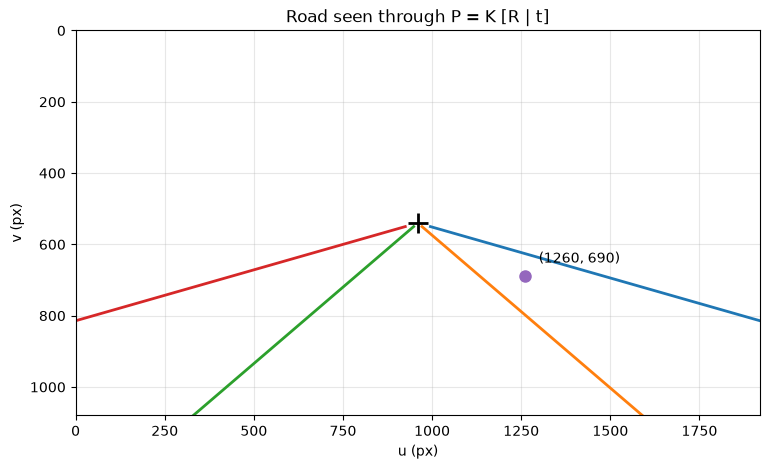

In [38]:
import matplotlib.pyplot as plt

d = np.linspace(3, 300, 300)                    
plt.figure(figsize=(9, 5))
for y in [-5.25, -1.75, 1.75, 5.25]:             
    pts = np.c_[d, np.full_like(d, y), np.zeros_like(d)]
    uv = project(P, pts)
    plt.plot(uv[:, 0], uv[:, 1], lw=2)

u, v = project(P, x_w)[0]
plt.plot(u, v, "o", ms=8)
plt.annotate(f"({u:.0f}, {v:.0f})", (u, v), xytext=(10, 10), textcoords="offset points")
plt.plot(960, 540, "k+", ms=14, mew=2)           
plt.xlim(0, 1920); plt.ylim(1080, 0)
plt.gca().set_aspect("equal")
plt.xlabel("u (px)"); plt.ylabel("v (px)")
plt.title("Road seen through P = K [R | t]")
plt.grid(alpha=0.3)
plt.show()

### Worked example 6 · Calibrating from the cube
91 cube corners give A with shape 182 × 12. The smallest eigenvalue of AᵀA is close to zero;
the next one is clearly larger.
Reprojecting all corners through the estimated P gives a mean error of 0.53 px (maximum 1.26
px), consistent with the 0.5 px detection noise that was added.
Reprojection error is the standard quality measure for any calibration: below about 0.5 px is
good.

Known 3D points on a calibration cube

In [40]:
import numpy as np
import matplotlib.pyplot as plt

def project(P,X):
    X = np.atleast_2d(np.asarray(X, float))
    Xh = np.hstack([X, np.ones((len(X),1))])
    x = (P @ Xh.T).T
    return x[:, :2] / x[:, 2:3]

g = np.linspace(0, 0.5, 6)
pts = []
for a in g:
    for b in g:
        pts += [[0.0, a, b], [a, 0.0, b], [a, b, 0.5]]
X_world = np.unique(np.array(pts), axis=0)
print("numbere of 3D points:", len(X_world))

numbere of 3D points: 91


Simulate a camera and the detected corners

In [41]:
K_true = np.array([[1200.0, 0, 640],
                   [0, 1180.0, 360],
                   [0, 0, 1]])
cam_c = np.array([-2.4, -2.0, 1.8])                
target = np.array([0.25, 0.25, 0.25])              

z_c = target - cam_c; z_c /= np.linalg.norm(z_c)    
x_c = np.cross(z_c, [0, 0, 1.0]); x_c /= np.linalg.norm(x_c)   
y_c = np.cross(z_c, x_c)                              
R_true = np.vstack([x_c, y_c, z_c])
t_true = -R_true @ cam_c
P_true = K_true @ np.hstack([R_true, t_true[:, None]])

rng = np.random.default_rng(7)
uv_detected = project(P_true, X_world) + rng.normal(0, 0.5, (len(X_world), 2))

DLT, building A and solving A p = 0

In [42]:
def build_A(X, uv):
    rows = []
    for (x, y, z), (u, v) in zip(X, uv):
        rows.append([x, y, z, 1, 0, 0, 0, 0, -u*x, -u*y, -u*z, -u])
        rows.append([0, 0, 0, 0, x, y, z, 1, -v*x, -v*y, -v*z, -v])
    return np.array(rows)

A = build_A(X_world, uv_detected)
eigvals, eigvecs = np.linalg.eigh(A.T @ A)     
P_est = eigvecs[:, 0].reshape(3, 4)           

print("A shape:", A.shape)                    
print("smallest eigenvalues:", eigvals[:3])   

A shape: (182, 12)
smallest eigenvalues: [0.00003794 0.01718855 0.03959231]


Reprojection error, the quality check

In [43]:
err = np.linalg.norm(project(P_est, X_world) - uv_detected, axis=1)
print(f"reprojection error: mean {err.mean():.2f} px, max {err.max():.2f} px")


reprojection error: mean 0.53 px, max 1.26 px


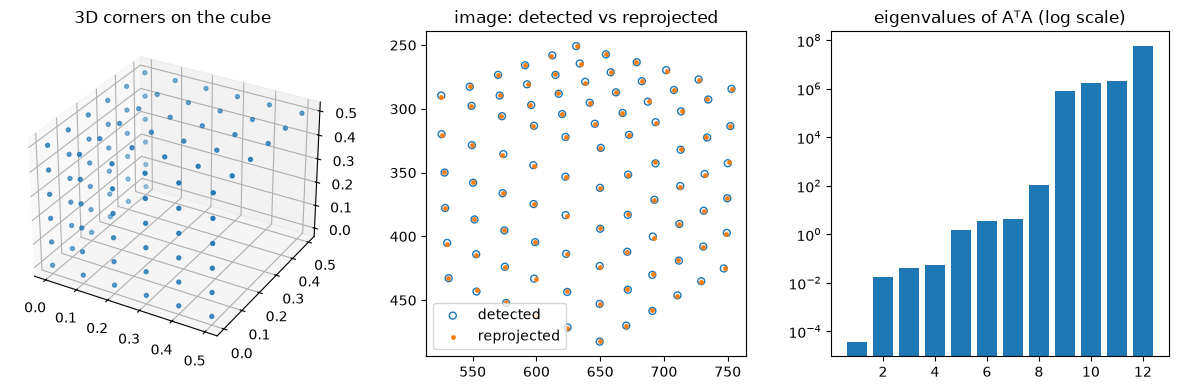

In [44]:
fig = plt.figure(figsize=(12, 4))

ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(*X_world.T, s=8)
ax.set_title("3D corners on the cube")

ax = fig.add_subplot(1, 3, 2)
uv_rep = project(P_est, X_world)
ax.scatter(*uv_detected.T, s=25, facecolors="none", edgecolors="tab:blue", label="detected")
ax.scatter(*uv_rep.T, s=6, color="tab:orange", label="reprojected")
ax.invert_yaxis(); ax.set_aspect("equal"); ax.legend()
ax.set_title("image: detected vs reprojected")

ax = fig.add_subplot(1, 3, 3)
ax.bar(range(1, 13), eigvals)
ax.set_yscale("log")
ax.set_title("eigenvalues of AᵀA (log scale)")
plt.tight_layout(); plt.show()

In [45]:
plane = X_world[np.isclose(X_world[:, 2], 0.5)]          # only the top face
A_plane = build_A(plane, project(P_true, plane))
print("points on one plane:", len(plane),
      " rank of A:", np.linalg.matrix_rank(A_plane), "(need 11)")

points on one plane: 36  rank of A: 8 (need 11)


### Worked example 7 · Decomposing the estimated P
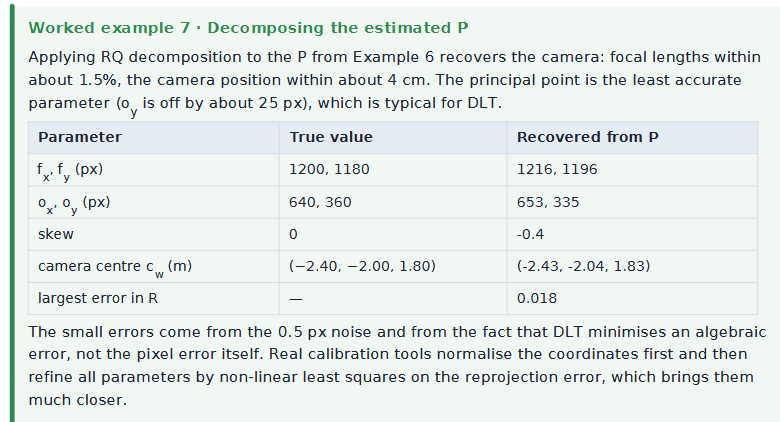

Decompose P into K, R and t

In [48]:
from scipy.linalg import rq
np.set_printoptions(suppress=True, precision=3)

def decompose(P):
    
    K, R = rq(P[:, :3])                    
    S = np.diag(np.sign(np.diag(K)))      
    K, R = K @ S, S @ R
    if np.linalg.det(R) < 0:               
        R, P = -R, -P
    t = np.linalg.solve(K, P[:, 3])        
    K = K / K[2, 2]                       
    return K, R, t

K_est, R_est, t_est = decompose(P_est)
cam_est = -R_est.T @ t_est

print(K_est)
print("largest error in R:", np.abs(R_est - R_true).max())
print("camera centre:", cam_est, " true:", cam_c)

[[1216.084   -0.447  653.068]
 [   0.    1196.395  335.254]
 [   0.       0.       1.   ]]
largest error in R: 0.017768096727465654
camera centre: [-2.432 -2.036  1.826]  true: [-2.4 -2.   1.8]


Two independent checks

In [49]:

_, _, Vt = np.linalg.svd(P_est)
C = Vt[-1]
print("null vector of P:", C[:3] / C[3])     


import cv2
Kc, Rc, Cc, *_ = cv2.decomposeProjectionMatrix(P_est)
print(Kc / Kc[2, 2])
print("camera centre:", (Cc[:3] / Cc[3]).ravel())   

null vector of P: [-2.432 -2.036  1.826]
[[-1216.084     0.447   653.068]
 [   -0.    -1196.395   335.254]
 [   -0.       -0.        1.   ]]
camera centre: [-2.432 -2.036  1.826]


Experiment, what limits the accuracy?

In [50]:
for noise in [0.0, 0.25, 0.5, 1.0, 2.0]:
    rng = np.random.default_rng(7)
    uv = project(P_true, X_world) + rng.normal(0, noise, (len(X_world), 2))
    A_ = build_A(X_world, uv)
    _, V = np.linalg.eigh(A_.T @ A_)
    K_, R_, t_ = decompose(V[:, 0].reshape(3, 4))
    cam_err = np.linalg.norm(-R_.T @ t_ - cam_c) * 100
    print(f"noise {noise:4.2f} px: fx={K_[0,0]:7.1f}  oy={K_[1,2]:6.1f}  camera error {cam_err:5.1f} cm")

noise 0.00 px: fx= 1200.0  oy= 360.0  camera error   0.0 cm
noise 0.25 px: fx= 1208.6  oy= 347.0  camera error   2.9 cm
noise 0.50 px: fx= 1216.1  oy= 335.3  camera error   5.5 cm
noise 1.00 px: fx= 1227.8  oy= 315.8  camera error   9.8 cm
noise 2.00 px: fx= 1236.9  oy= 295.3  camera error  15.0 cm
